# Classifying the CIFAR10 Dataset

Assignment from *Programming Exercises Chapter 14*, Stijn Lievens and Simon De Gheselle (June 26, 2026). 

In [1]:
import keras
import numpy as np

## 1.1 Load the Data

Load the built-in Keras CIFAR10 dataset. See https://keras.io/api/datasets/cifar10/#load_data-function. Use the supplied code:
```python
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.cifar10.load_data()
```

In [2]:
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.cifar10.load_data()



Check the shapes of the training and test sets. Interpret what every dimension means.

In [3]:
print(
  X_train_full.shape,
  y_train_full.shape,
  X_test.shape,
  y_test.shape
)

print(y_train_full[0])

# X_.. bevat 50 000 afbeeldingen met 32x32 pixels. each pixel has 3 values (RGB). test set is 10 000 afbeeldingen groot.


(50000, 32, 32, 3) (50000, 1) (10000, 32, 32, 3) (10000, 1)
[6]


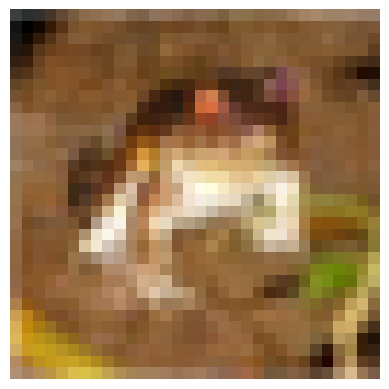

In [4]:
import matplotlib.pyplot as plt

plt.imshow(X_train_full[0,])
plt.axis("off")
plt.show()

Use the last 10,000 training examples as validation data and the remaining examples as training data. Create both sets.

In [5]:
X_val = X_train_full[40_000:]
y_val = y_train_full[40_000:]
X_train = X_train_full[:40_000]
y_train = y_train_full[:40_000]

In [6]:
X_val.shape
X_train.shape

(40000, 32, 32, 3)

## 1.2 Some Data Exploration

Give the number of examples in each of the ten categories.

In [7]:
class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

unique, counts = np.unique_counts(y_train)

In [8]:
for i in range(len(class_names)):
  print(class_names[i], "  ", counts[i])

airplane    3986
automobile    3986
bird    4048
cat    3984
deer    4003
dog    3975
frog    4020
horse    4023
ship    3997
truck    3978


Show the first 25 examples in a 5 × 5 grid, with the class label above each image. Supplied class names:
```python
class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]
```

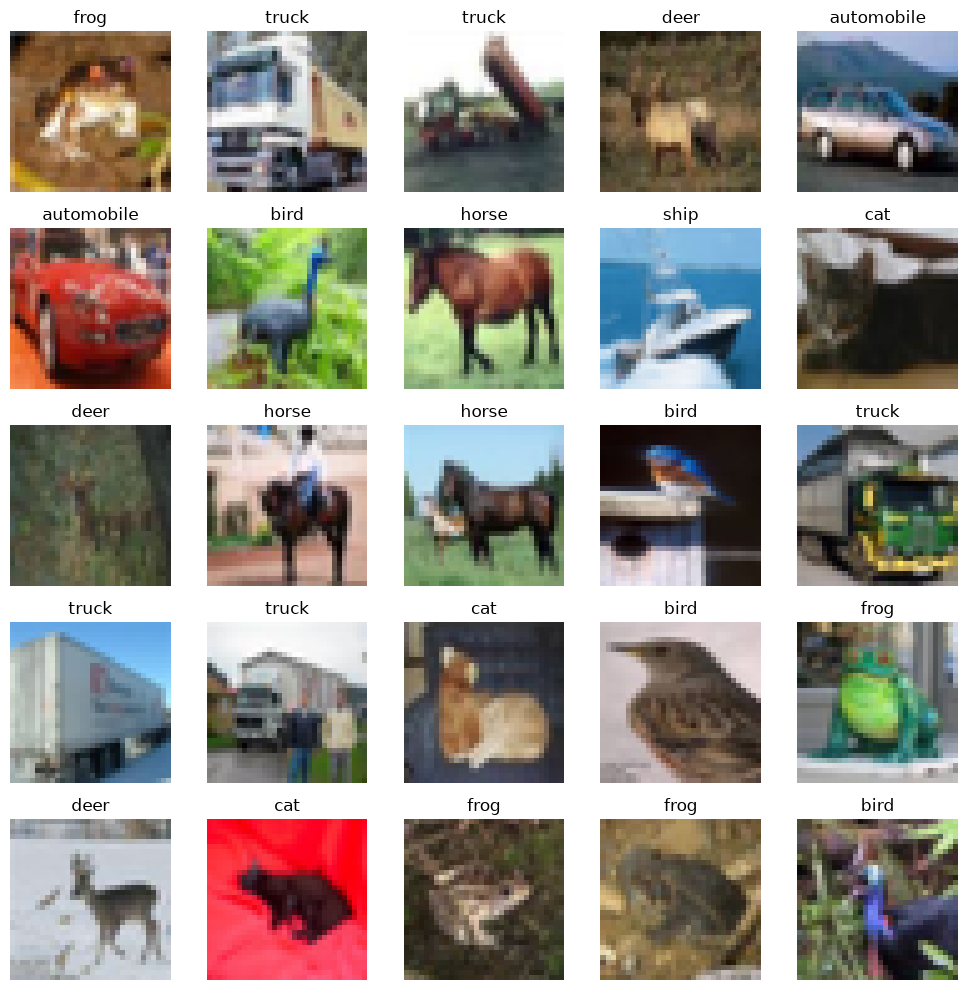

In [9]:
fig, axes = plt.subplots(5, 5, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_full[i])
    ax.set_title(class_names[int(y_train_full[i, 0])])
    ax.axis("off")

fig.tight_layout()
plt.show()

## 1.3 Build a Model

Write `get_model()` using the Sequential API with this architecture:

- Input specifying the image shape.
- Rescaling from [0, 255] to [0, 1].
- Two Conv2D layers, each with 32 filters, (3, 3) kernels, same padding, and ReLU.
- Max pooling with pool size (2, 2).
- Two Conv2D layers, each with 64 filters, (3, 3) kernels, same padding, and ReLU.
- Max pooling with pool size (2, 2).
- Flatten.
- Dense with 128 units and ReLU.
- Dense output layer.

How many output units and which activation function are appropriate for classification into ten classes?

In [10]:
def get_model():
  model = keras.models.Sequential()
  
  model.add(keras.layers.Input(shape=(32,32,3)))
  model.add(keras.layers.Rescaling(scale=1./255, offset=0))
  model.add(keras.layers.Conv2D(filters=32, kernel_size=(3,3), padding="same", activation='relu'))
  model.add(keras.layers.Conv2D(filters=32, kernel_size=(3,3), padding="same", activation='relu'))
  model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))
  model.add(keras.layers.Conv2D(filters=64, kernel_size=(3,3), padding="same", activation='relu'))
  model.add(keras.layers.Conv2D(filters=64, kernel_size=(3,3), padding="same", activation='relu'))
  model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))
  model.add(keras.layers.Flatten())
  model.add(keras.layers.Dense(units=128, activation='relu'))
  model.add(keras.layers.Dense(units=10, activation="softmax"))
  
  return model
  

Create an instance and verify that it has 591,274 parameters.

In [11]:
model = get_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 591,274 (2.26 MB)

 Trainable params: 591,274 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

## 1.4 Compile the Model

Compile using Adam with learning rate 0.001. Choose the correct classification loss and track the percentage of correctly classified images.

In [12]:
model.compile(
  optimizer=keras.optimizers.Adam(learning_rate=0.001),
  loss="sparse_categorical_crossentropy",
  metrics=['accuracy']
)

## 1.5 Train the Model

Train for a large number of epochs, using early stopping and the validation data to prevent severe overfitting.

In [13]:
history = model.fit(
  x=X_train,
  y=y_train,
  epochs=50,
  callbacks=[keras.callbacks.EarlyStopping(patience=3,restore_best_weights=True)],
  validation_data=[X_val, y_val]
)

Epoch 1/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 27s 22ms/step - accuracy: 0.4885 - loss: 1.4039 - val_accuracy: 0.6170 - val_loss: 1.0855
Epoch 2/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 31s 25ms/step - accuracy: 0.6529 - loss: 0.9711 - val_accuracy: 0.6893 - val_loss: 0.8985
Epoch 3/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 31s 24ms/step - accuracy: 0.7225 - loss: 0.7925 - val_accuracy: 0.6864 - val_loss: 0.9236
Epoch 4/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 33s 26ms/step - accuracy: 0.7727 - loss: 0.6569 - val_accuracy: 0.7139 - val_loss: 0.8559
Epoch 5/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.8098 - loss: 0.5482 - val_accuracy: 0.7192 - val_loss: 0.8935
Epoch 6/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 33s 27ms/step - accuracy: 0.8431 - loss: 0.4521 - val_accuracy: 0.7098 - val_loss: 1.0278
Epoch 7/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 34s 27ms/step - accuracy: 0.8680 - loss: 0.3741 - val_accuracy: 0.7202 - val_loss: 1.0475


Use the history returned by `fit()` to plot the learning curves. The supplied plotting helper is reproduced below.

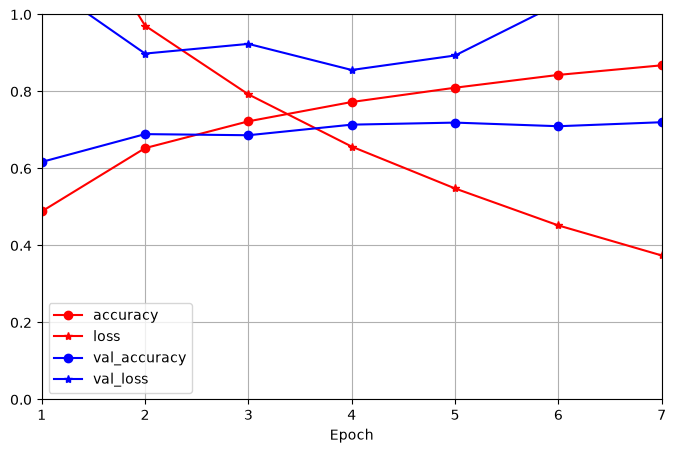

In [14]:
def plot_learning_curves ( history ):
  plt.figure( figsize =(8, 5))
  for key , style in zip (history .history , [ "r-o", "r-*", "b-o", "b-*"]):
    epochs = np.array( history .epoch)
    plt.plot(epochs + 1, history. history [key], style , label=key)
  plt.xlabel( "Epoch")
  plt.axis ([1, len (history . history [ "loss"]), 0., 1])
  plt.legend(loc= "lower left")
  plt.grid ()

plot_learning_curves(history)

### Supplied plotting helper

```python
def plot_learning_curves ( history ):
plt.figure( figsize =(8, 5))
for key , style in zip (history .history , [ "r-o", "r-* ", "b-o", "b-* "]):
epochs = np.array( history .epoch)
plt.plot(epochs + 1, history. history [key], style , label=key)
plt.xlabel( "Epoch ")
plt.axis ([1, len (history . history [ "loss "]), 0., 1])
plt.legend(loc= "lower left ")
plt.grid ()
```

## 1.6 Evaluate the Model

Evaluate on the test set with `evaluate()`. What is the performance?

In [15]:
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7074 - loss: 0.8976


[0.8976313471794128, 0.7074000239372253]

Implement `get_predictions(model, X, keepdims=False)` in at most two lines. `X` has shape `(batch_size, height, width, channels)`. Return predicted class labels of shape `(batch_size,)`, or `(batch_size, 1)` when `keepdims=True`.

In [16]:
def get_predictions(model, X, keepdims=False):
    return np.argmax(model.predict(X, verbose=0), axis=1, keepdims=keepdims)

Use this function to calculate validation accuracy by comparing with `y_valid`. Recognize the corresponding number from the `fit()` output.

In [17]:
y_val_pred = get_predictions(model, X_val, keepdims=True)
validation_accuracy = np.mean(y_val_pred == y_val)

print(validation_accuracy)

0.7139


Implement `get_incorrectly_predicted_images(model, X, y_true)`. Inputs are images of shape `(n, image_shape)` and labels of shape `(n, 1)` or `(n,)`. Return incorrectly classified images, predicted labels, and expected labels, with shapes `(m, image_shape)`, `(m,)`, and `(m,)`.

In [18]:
def get_incorrectly_predicted_images(model, X, y_true):
    predictions = get_predictions(model, X)
    y_true = np.asarray(y_true).ravel()
    incorrect = predictions != y_true
    return X[incorrect], predictions[incorrect], y_true[incorrect]

test set: Plot 25 wrongly classified images in a 5 × 5 grid, showing predicted and actual classes above each image.

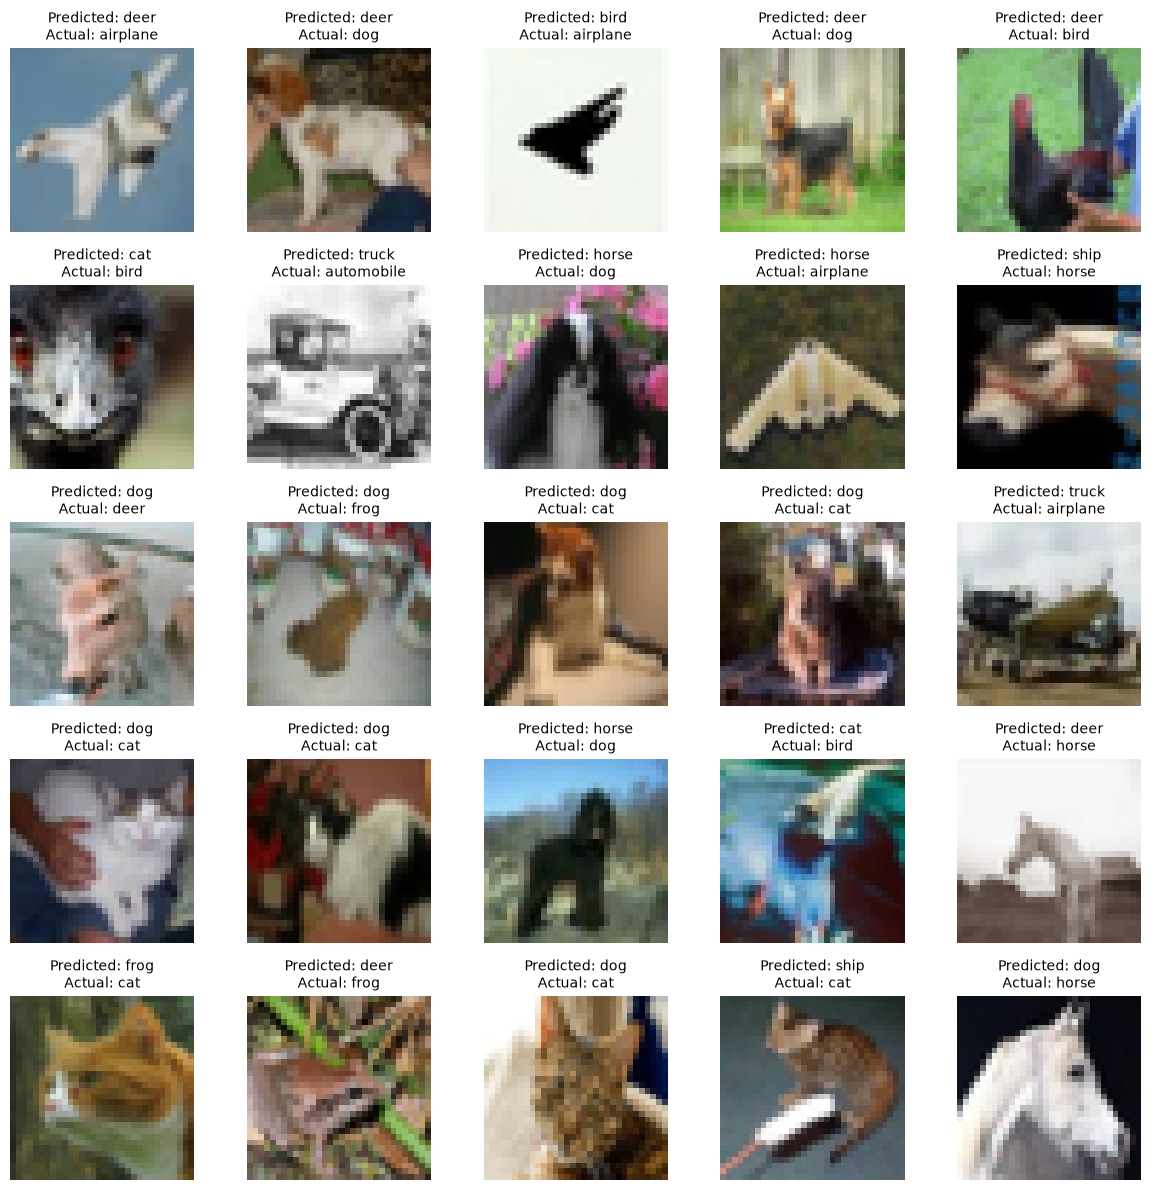

In [19]:
X_wrong, y_pred_wrong, y_true_wrong = get_incorrectly_predicted_images(
    model, X_test, y_test
)

fig, axes = plt.subplots(5, 5, figsize=(12, 12))
for i, ax in enumerate(axes.flat):
    ax.axis("off")
    if i < len(X_wrong):
        ax.imshow(X_wrong[i])
        ax.set_title(
            f"Predicted: {class_names[y_pred_wrong[i]]}\n"
            f"Actual: {class_names[y_true_wrong[i]]}",
            fontsize=10
        )

fig.tight_layout()
plt.show()

### Part 6

Use a TensorFlow method to create the test confusion matrix, with actual classes in rows and predicted classes in columns. Display it using the supplied Seaborn plotting code below.

In [20]:
import tensorflow as tf
import seaborn as sns

y_test_pred = get_predictions(model, X_test)
cm = tf.math.confusion_matrix(
    labels=y_test.ravel(),
    predictions=y_test_pred,
    num_classes=len(class_names)
)

cm

<tf.Tensor: shape=(10, 10), dtype=int32, numpy=
array([[738,  27,  43,  14,  34,   7,  12,  11,  45,  69],
       [  8, 826,   3,   2,   5,   3,   5,   4,  12, 132],
       [ 64,  10, 443,  46, 187,  97,  89,  38,  12,  14],
       [ 21,  20,  28, 370, 144, 247,  79,  55,   8,  28],
       [ 10,   4,  20,  26, 771,  45,  43,  74,   4,   3],
       [  7,   6,  18,  84,  66, 691,  33,  76,   4,  15],
       [  7,   8,  21,  30,  84,  36, 792,  10,   4,   8],
       [  8,   0,  14,  15,  82,  59,   7, 796,   1,  18],
       [ 63,  60,   9,   6,  23,   8,   3,   7, 761,  60],
       [ 12,  50,   3,   5,   9,   8,   6,  14,   7, 886]], dtype=int32)>

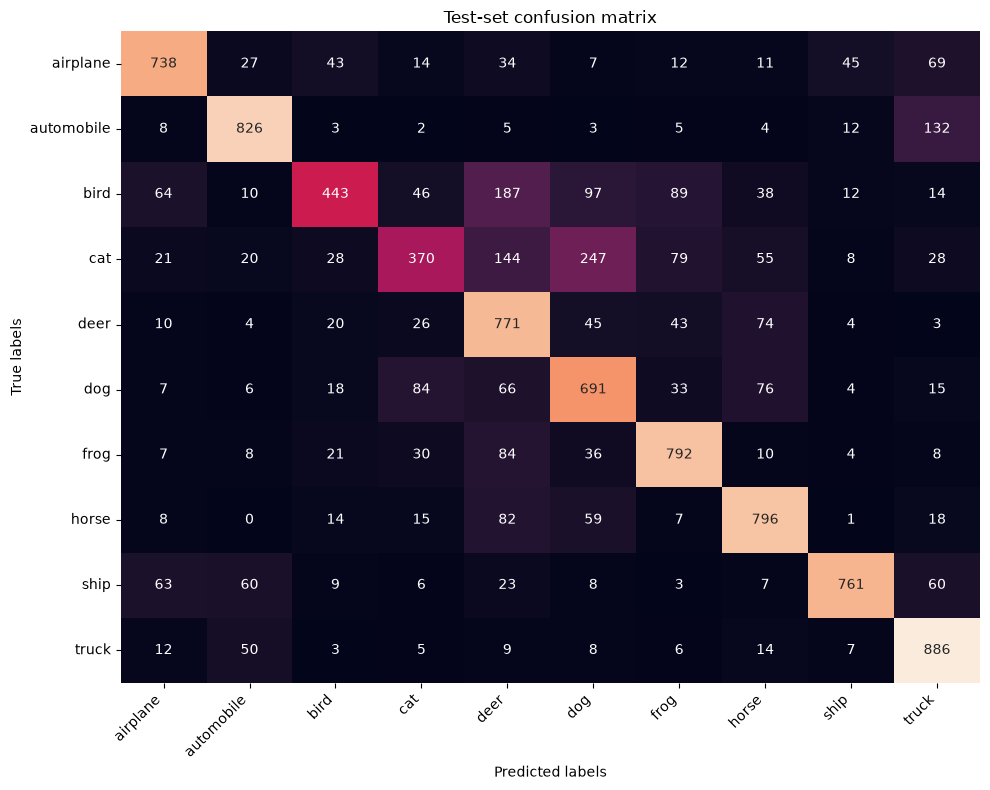

In [21]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    cm.numpy(), annot=True, fmt="d", ax=ax, cbar=False,
    xticklabels=class_names, yticklabels=class_names
)
ax.set_xlabel("Predicted labels")
ax.set_ylabel("True labels")
ax.set_title("Test-set confusion matrix")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
plt.show()

### Supplied confusion-matrix display code

```python
cm = # YOUR CODE HERE
ax = plt. subplot ()
#annot =True to annotate cells , ftm =" g" to disable scientific notation
sns. heatmap (cm , annot=True , fmt= "g", ax=ax , cbar=False);
# labels , title and ticks
ax. set_xlabel ( "Predicted labels ");ax. set_ylabel ( "True labels ");
ax. set_title ( "Confusion Matrix ");
ax.xaxis. set_ticklabels (class_names , rotation = -45);
ax.yaxis. set_ticklabels (class_names , rotation =0);

```

## 1.7 Try to Improve the Model

Try to obtain higher accuracy. Suggested experiments: add a convolutional block; add dropout (Chapter 11); try different weight initialization; continue training with a smaller learning rate; use Monte Carlo dropout.

In [22]:
model_baseline = model
history_baseline = history

experiments = {
    "baseline": {
        "model": model_baseline,
        "history": history_baseline,
    }
}

### 1.7.1 add a convolutional block, or two

In [23]:
def get_model_conv():
  model = keras.models.Sequential()
  
  model.add(keras.layers.Input(shape=(32,32,3)))
  model.add(keras.layers.Rescaling(scale=1./255, offset=0))
  model.add(keras.layers.Conv2D(filters=32, kernel_size=(3,3), padding="same", activation='relu'))
  model.add(keras.layers.Conv2D(filters=32, kernel_size=(3,3), padding="same", activation='relu'))
  model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))
  model.add(keras.layers.Conv2D(filters=64, kernel_size=(3,3), padding="same", activation='relu'))
  model.add(keras.layers.Conv2D(filters=64, kernel_size=(3,3), padding="same", activation='relu'))
  model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))
  model.add(keras.layers.Conv2D(filters=128, kernel_size=(3,3), padding="same", activation='relu'))
  model.add(keras.layers.Conv2D(filters=128, kernel_size=(3,3), padding="same", activation='relu'))
  model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))
  model.add(keras.layers.Conv2D(filters=256, kernel_size=(3,3), padding="same", activation='relu'))
  model.add(keras.layers.Conv2D(filters=256, kernel_size=(3,3), padding="same", activation='relu'))
  model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))
  model.add(keras.layers.Flatten())
  model.add(keras.layers.Dense(units=128, activation='relu'))
  model.add(keras.layers.Dense(units=10, activation="softmax"))
  
  return model

model_conv = get_model_conv()

model_conv.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 4, 4, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 4, 4, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,304,746 (4.98 MB)

 Trainable params: 1,304,746 (4.98 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
def compile_and_fit(model):
  model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=['accuracy']
  )

  history = model.fit(
    x=X_train,
    y=y_train,
    epochs=50,
    callbacks=[keras.callbacks.EarlyStopping(patience=3,restore_best_weights=True)],
    validation_data=[X_val, y_val]
  )
  
  return history

In [25]:
compile_and_fit(model_conv)


Epoch 1/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 68s 54ms/step - accuracy: 0.3414 - loss: 1.7374 - val_accuracy: 0.4557 - val_loss: 1.4646
Epoch 2/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 64s 52ms/step - accuracy: 0.5340 - loss: 1.2627 - val_accuracy: 0.5943 - val_loss: 1.1405
Epoch 3/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 65s 52ms/step - accuracy: 0.6287 - loss: 1.0323 - val_accuracy: 0.6595 - val_loss: 0.9731
Epoch 4/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 69s 56ms/step - accuracy: 0.6907 - loss: 0.8669 - val_accuracy: 0.6969 - val_loss: 0.8920
Epoch 5/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 66s 53ms/step - accuracy: 0.7400 - loss: 0.7324 - val_accuracy: 0.7128 - val_loss: 0.8636
Epoch 6/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 65s 52ms/step - accuracy: 0.7730 - loss: 0.6385 - val_accuracy: 0.7139 - val_loss: 0.9073
Epoch 7/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 68s 55ms/step - accuracy: 0.7965 - loss: 0.5692 - val_accuracy: 0.6925 - val_loss: 1.0707
Epoch 8/50
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 74s 59ms/step - accuracy: 0.8189 -

In [26]:
model_conv.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.7058 - loss: 0.8872


[0.8871744871139526, 0.7057999968528748]